### 0. Required run configuration

All experiment settings are explicit here. Validation rejects missing, blank, or invalid values.
The values below preserve the current architecture and 55-epoch experiment, with
batch size 16 and cosine LR from 1e-4 toward 1e-6. Edit this cell before execution.
The recorded 9-state / 15-by-716 scan layout is a fixed data contract.

In [44]:
from pathlib import Path
import copy
import json
import math
import random
import sys

# Edit these explicit settings before running the notebook.
# Missing, blank, or invalid settings stop execution before data loading/training.
CONFIG = {
    "paths": {
        "repo_root": r"A:\Projects\ARES",
        "output_root": r"A:\Projects\ARES\results\output_directoryZ",
    },
    "run": {"name": "CNN_MLP_BASELINE", "seed": 42},
    "data": {
        "batch_id": "c3eaab07-d882-4825-98a5-84c278cf8935",
        "expected_episodes": 80,
        "train_fraction": 0.8,
        "val_fraction": 0.2,
        "split_seed": 42,
        "verify_hashes": True,
    },
    "model": {
        "input_features": 12,
        "hidden_activation": "gelu",
        "encoder_hidden": [128, 256],
        "latent_channels": 128,
        "latent_length": 45,
        "decoder_channels": [128, 128, 64, 32, 15],
        "decoder_lengths": [90, 179, 358, 716, 716],
        "kernel_sizes": [5, 5, 3, 3, 3],
        "upsample_mode": "linear",
        "align_corners": False,
        "output_activation": "gelu",
    },
    "training": {
        "optimizer": "adamw",
        "loss": "mse",
        "epochs": 55,
        "batch_size": 16,
        "learning_rate": 1e-4,
        "weight_decay": 1e-4,
        "betas": [0.9, 0.999],
        "eps": 1e-8,
        "patience": 10,
        "save_every_n_epochs": 0,  # 0 = best.pt + last.pt; >0 adds numbered checkpoints.
    },
    "scheduler": {
        "name": "cosine",
        "t_max_epochs": 55,
        "min_lr": 1e-6,
    },
    "runtime": {
        "gpu_index": 0,
        "amp_dtype": "bf16",
        "num_workers": 0,
        "pin_memory": True,
        "persistent_workers": False,
        "cudnn_benchmark": True,
        "matmul_precision": "high",
        "fused_adamw": True,
    },
    "plots": {
        "dpi": 160,
        "scan_index": 0,
        "range_min_m": 0.0,
        "range_max_m": 7.0,
        "colormap": "viridis",
    },
}


def validate_config(config):
    required = {
        "paths": ("repo_root", "output_root"),
        "run": ("name", "seed"),
        "data": ("batch_id", "expected_episodes", "train_fraction", "val_fraction",
                 "split_seed", "verify_hashes"),
        "model": ("input_features", "hidden_activation", "encoder_hidden", "latent_channels", "latent_length",
                  "decoder_channels", "decoder_lengths", "kernel_sizes",
                  "upsample_mode", "align_corners", "output_activation"),
        "training": ("optimizer", "loss", "epochs", "batch_size", "learning_rate", "weight_decay",
                     "betas", "eps", "patience", "save_every_n_epochs"),
        "scheduler": ("name", "t_max_epochs", "min_lr"),
        "runtime": ("gpu_index", "amp_dtype", "num_workers", "pin_memory",
                    "persistent_workers", "cudnn_benchmark", "matmul_precision",
                    "fused_adamw"),
        "plots": ("dpi", "scan_index", "range_min_m", "range_max_m", "colormap"),
    }
    for section, keys in required.items():
        if section not in config or not isinstance(config[section], dict):
            raise ValueError(f"Missing configuration section: {section}")
        for key in keys:
            if key not in config[section]:
                raise ValueError(f"Missing configuration: {section}.{key}")

    def check_filled(value, path):
        if value is None or (isinstance(value, str) and not value.strip()):
            raise ValueError(f"Fill configuration before execution: {path}")
        if isinstance(value, dict):
            for key, item in value.items():
                check_filled(item, f"{path}.{key}")
        elif isinstance(value, (list, tuple)):
            if not value:
                raise ValueError(f"Empty configuration: {path}")
            for i, item in enumerate(value):
                check_filled(item, f"{path}[{i}]")
        elif isinstance(value, float) and not math.isfinite(value):
            raise ValueError(f"Non-finite configuration: {path}")
    check_filled(config, "CONFIG")

    def integer(value, label, minimum):
        if isinstance(value, bool) or not isinstance(value, int) or value < minimum:
            raise ValueError(f"{label} must be an integer >= {minimum}.")

    def number(value, label, minimum, *, positive=False):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"{label} must be numeric.")
        if not math.isfinite(value) or value < minimum or (positive and value == minimum):
            raise ValueError(f"Invalid numeric value: {label}")

    for section, keys, minimum in (
        ("run", ("seed",), 0),
        ("data", ("expected_episodes",), 2),
        ("data", ("split_seed",), 0),
        ("training", ("epochs", "batch_size", "patience"), 1),
        ("training", ("save_every_n_epochs",), 0),
        ("scheduler", ("t_max_epochs",), 1),
        ("runtime", ("gpu_index", "num_workers"), 0),
        ("plots", ("scan_index",), 0),
        ("plots", ("dpi",), 1),
    ):
        for key in keys:
            integer(config[section][key], f"{section}.{key}", minimum)

    d, m, t, s, r, p = (config[key] for key in
                         ("data", "model", "training", "scheduler", "runtime", "plots"))
    for key in ("train_fraction", "val_fraction"):
        number(d[key], f"data.{key}", 0, positive=True)
    if not math.isclose(d["train_fraction"] + d["val_fraction"], 1, rel_tol=0, abs_tol=1e-12):
        raise ValueError("Train/validation fractions must sum to 1.")
    if d["expected_episodes"] % 2:
        raise ValueError("The recorded North/East episode count must be even.")
    if m["input_features"] != 12:
        raise ValueError("Sine/cosine state encoding requires 12 model inputs.")
    for key in ("latent_channels", "latent_length"):
        integer(m[key], f"model.{key}", 1)
    for key in ("encoder_hidden", "decoder_channels", "decoder_lengths", "kernel_sizes"):
        if not isinstance(m[key], (list, tuple)) or not m[key]:
            raise ValueError(f"model.{key} must be a nonempty sequence.")
        for value in m[key]:
            integer(value, f"model.{key}", 1)
    if not (len(m["decoder_channels"]) == len(m["decoder_lengths"]) == len(m["kernel_sizes"])):
        raise ValueError("Decoder channels, lengths and kernel lists must have equal lengths.")
    if any(k % 2 == 0 for k in m["kernel_sizes"]):
        raise ValueError("Use odd convolution kernels to preserve sequence lengths.")
    if m["decoder_channels"][-1] != 15 or m["decoder_lengths"][-1] != 716:
        raise ValueError("The recorded target shape is [15, 716].")
    if m["upsample_mode"] != "linear" or not isinstance(m["align_corners"], bool):
        raise ValueError("This decoder uses linear interpolation and a boolean align_corners.")
    if m["hidden_activation"] not in ("gelu", "relu", "silu"):
        raise ValueError("Choose hidden_activation: gelu, relu or silu.")
    if t["optimizer"] != "adamw" or t["loss"] != "mse":
        raise ValueError("This trainer uses AdamW and MSE loss.")
    if m["output_activation"] not in ("gelu", "identity", "softplus"):
        raise ValueError("Choose output_activation: gelu, identity or softplus.")
    for key in ("learning_rate", "eps"):
        number(t[key], f"training.{key}", 0, positive=True)
    number(t["weight_decay"], "training.weight_decay", 0)
    if not isinstance(t["betas"], (list, tuple)) or len(t["betas"]) != 2:
        raise ValueError("training.betas must contain two values.")
    for value in t["betas"]:
        number(value, "training.betas", 0)
        if value >= 1:
            raise ValueError("AdamW betas must be below 1.")
    number(s["min_lr"], "scheduler.min_lr", 0)
    if s["name"] != "cosine" or s["t_max_epochs"] < t["epochs"]:
        raise ValueError("Use cosine with t_max_epochs >= training.epochs to avoid LR rising again.")
    if s["min_lr"] >= t["learning_rate"]:
        raise ValueError("scheduler.min_lr must be below the initial learning rate.")
    for section, key in (("data", "verify_hashes"), ("runtime", "pin_memory"),
                         ("runtime", "persistent_workers"), ("runtime", "cudnn_benchmark"),
                         ("runtime", "fused_adamw")):
        if not isinstance(config[section][key], bool):
            raise ValueError(f"{section}.{key} must be boolean.")
    if r["persistent_workers"] and r["num_workers"] == 0:
        raise ValueError("persistent_workers requires num_workers > 0.")
    if r["amp_dtype"] not in ("bf16", "fp16"):
        raise ValueError("runtime.amp_dtype must be bf16 or fp16.")
    if r["matmul_precision"] not in ("highest", "high", "medium"):
        raise ValueError("Invalid runtime.matmul_precision.")
    number(p["range_min_m"], "plots.range_min_m", 0)
    number(p["range_max_m"], "plots.range_max_m", 0, positive=True)
    if p["range_max_m"] <= p["range_min_m"]:
        raise ValueError("Plot maximum must exceed minimum.")
    for section, key in (("paths", "repo_root"), ("paths", "output_root"),
                         ("run", "name"), ("data", "batch_id"), ("plots", "colormap")):
        if not isinstance(config[section][key], str):
            raise ValueError(f"{section}.{key} must be a string.")
    for label, value in (("run.name", config["run"]["name"]), ("data.batch_id", d["batch_id"])):
        if value in (".", "..") or any(c in value for c in '<>:"/\\|?*'):
            raise ValueError(f"{label} must be a Windows-safe single folder name.")
    json.dumps(config, allow_nan=False)
    return config


validate_config(CONFIG)
REPO_ROOT = Path(CONFIG["paths"]["repo_root"]).expanduser().resolve()
BATCH_ID = CONFIG["data"]["batch_id"]
OUTPUT_ROOT = Path(CONFIG["paths"]["output_root"]).expanduser().resolve()
print("Configuration validated. Output root:", OUTPUT_ROOT)


Configuration validated. Output root: A:\Projects\ARES\results\output_directoryZ


### 1. Locate the configured checkout

In [45]:
import os
import platform
import shutil
import subprocess

PYTHON = Path(sys.executable).resolve()
required = [
    REPO_ROOT / "scripts" / "colab_episode_starter.py",
    REPO_ROOT / "scripts" / "ares_safe_training" / "data.py",
    REPO_ROOT / "data" / "batches" / BATCH_ID / "python_index.csv",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing project inputs: " + repr(missing))
scripts_path = str(REPO_ROOT / "scripts")
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)
print("Notebook kernel:", PYTHON)
print("Platform:", platform.platform())
print("Checkout:", REPO_ROOT)


Notebook kernel: A:\Projects\ARES\.venv\Scripts\python.exe
Platform: Windows-10-10.0.26200-SP0
Checkout: A:\Projects\ARES


### 2. Check packages and CUDA

In [46]:
import importlib.util
from importlib.metadata import version as package_version

required_packages = ("numpy", "pandas", "torch", "matplotlib")
missing = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Install these packages in the active notebook environment: " + repr(missing))
print({name: package_version(name) for name in required_packages})


{'numpy': '2.4.6', 'pandas': '3.1.1', 'torch': '2.11.0+cu128', 'matplotlib': '3.11.2'}


In [47]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from colab_episode_starter import EpisodeDataset

if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 5):
    raise RuntimeError("This notebook requires PyTorch >= 2.5.")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable in this notebook kernel.")
if CONFIG["runtime"]["gpu_index"] >= torch.cuda.device_count():
    raise ValueError("Configured GPU index is unavailable.")
torch.cuda.set_device(CONFIG["runtime"]["gpu_index"])
if CONFIG["runtime"]["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
    raise ValueError("Configured BF16 is unsupported; select fp16 explicitly.")
if CONFIG["plots"]["colormap"] not in plt.colormaps():
    raise ValueError("Unknown plots.colormap.")
print("GPU:", torch.cuda.get_device_name(CONFIG["runtime"]["gpu_index"]))
print("AMP:", CONFIG["runtime"]["amp_dtype"])


GPU: NVIDIA GeForce RTX 4080 Laptop GPU
AMP: bf16


### 3. Model and angle preprocessing

The diagram shows 9 raw state values. Sine/cosine encoding expands these to
12 features before the MLP. Channel sizes and activations come from CONFIG.

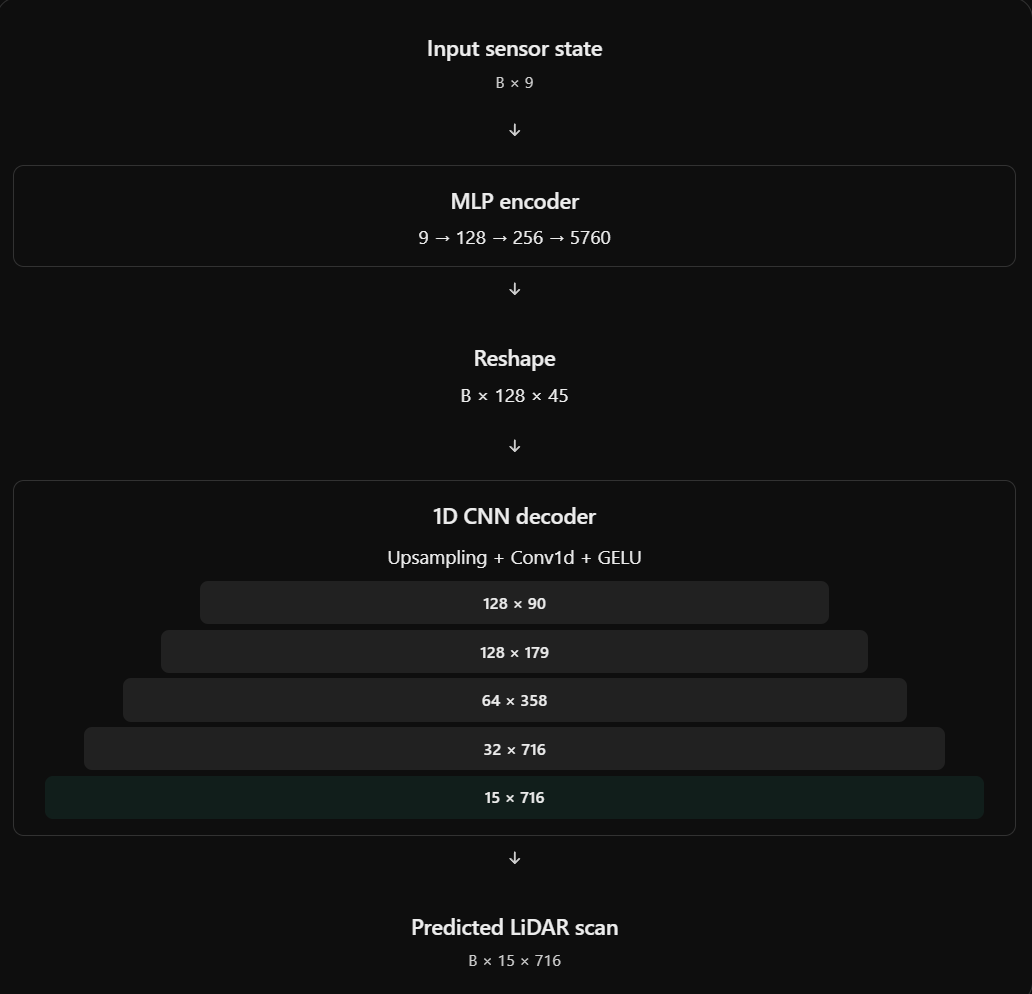

In [48]:
###################################################################
## PRE-PROCESSING FUNCTION
###################################################################
def encode_sensor_state(raw_states):
    
    if raw_states.ndim < 1 or raw_states.shape[-1] != 9:
        raise ValueError(
            "Expected raw sensor states with last dimension 9."
        )

    raw_states = raw_states.float()
    angles = raw_states[..., 6:9]

    angle_features = torch.stack((torch.sin(angles), torch.cos(angles)), dim=-1)
    angle_features = angle_features.flatten(start_dim=-2)

    return torch.cat((raw_states[..., :6], angle_features), dim=-1)

In [49]:
class PoseToRangeCNN(nn.Module):
    """12 encoded state features -> [batch, 15, 716] scan."""
    def __init__(self, model_config):
        super().__init__()
        self.model_config = copy.deepcopy(model_config)
        c = self.model_config
        activation_types = {"gelu": nn.GELU, "relu": nn.ReLU, "silu": nn.SiLU,
                            "identity": nn.Identity, "softplus": nn.Softplus}
        self.latent_channels = c["latent_channels"]
        self.latent_length = c["latent_length"]

        widths = [c["input_features"], *c["encoder_hidden"],
                  self.latent_channels * self.latent_length]
        encoder = []
        for in_features, out_features in zip(widths[:-1], widths[1:]):
            encoder.extend([nn.Linear(in_features, out_features), activation_types[c["hidden_activation"]]()])
        self.encoder = nn.Sequential(*encoder)

        decoder = []
        in_channels = self.latent_channels
        last = len(c["decoder_channels"]) - 1
        for i, (out_channels, length, kernel) in enumerate(zip(
            c["decoder_channels"], c["decoder_lengths"], c["kernel_sizes"]
        )):
            decoder.extend([
                nn.Upsample(size=length, mode=c["upsample_mode"],
                            align_corners=c["align_corners"]),
                nn.Conv1d(in_channels, out_channels, kernel_size=kernel,
                          padding=kernel // 2),
            ])
            activation = c["hidden_activation"] if i != last else c["output_activation"]
            decoder.append(activation_types[activation]())
            in_channels = out_channels
        self.decoder = nn.Sequential(*decoder)

    def forward(self, sensor_state):
        features = self.encoder(sensor_state)
        features = features.reshape(
            sensor_state.shape[0], self.latent_channels, self.latent_length
        )
        return self.decoder(features)


In [50]:
# Verify the complete raw-state -> angle encoding -> scan prediction path.
check_device = torch.device("cuda", CONFIG["runtime"]["gpu_index"])
with torch.inference_mode():
    check_model = PoseToRangeCNN(CONFIG["model"]).to(check_device)
    check_states = torch.zeros(2, 9, device=check_device)
    check_output = check_model(encode_sensor_state(check_states))
    assert check_output.shape == (2, 15, 716)
    print("Verified model output:", tuple(check_output.shape))
del check_model, check_states, check_output


Verified model output: (2, 15, 716)


In [51]:
import csv
import logging
import os
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
from matplotlib.ticker import MaxNLocator


def seed_training(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def write_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    try:
        temporary.write_text(
            json.dumps(value, indent=2, allow_nan=False), encoding="utf-8"
        )
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def save_checkpoint(path, checkpoint):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    try:
        torch.save(checkpoint, temporary)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def create_training_logger(log_file):
    logger = logging.Logger("pose_to_range", level=logging.INFO)
    logger.propagate = False
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S"
    )
    for handler in (
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(log_file, encoding="utf-8"),
    ):
        handler.setFormatter(formatter)
        logger.addHandler(handler)
    return logger


def log_epoch(logger, *, epoch, epochs, train_mse, val_mse, val_mae,
              learning_rate, elapsed_s, improved, stale_epochs, patience):
    status = "BEST" if improved else f"stale={stale_epochs}/{patience}"
    logger.info(
        "epoch=%03d/%03d | train_mse=%.5f | val_mse=%.5f | "
        "val_rmse=%.4f | val_mae=%.4f | lr=%.2e | %.1fs | %s",
        epoch, epochs, train_mse, val_mse, math.sqrt(val_mse),
        val_mae, learning_rate, elapsed_s, status,
    )


def plot_run_history(run_dir, *, show):
    """Read persisted metrics; works after restarting the notebook kernel."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    history = json.loads((run_dir / "metrics.json").read_text(encoding="utf-8"))
    if not history["epoch"]:
        raise ValueError("This run has no completed epochs to plot.")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    best_index = int(np.argmin(history["val_mse"]))
    best_epoch = history["epoch"][best_index]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for ax, keys, title, ylabel in (
        (axes[0], ("train_mse", "val_mse"), "Training and validation loss", "MSE (m²)"),
        (axes[1], ("train_rmse", "val_rmse"), "Training and validation range error", "RMSE (m)"),
    ):
        for key, label in zip(keys, ("Train", "Validation")):
            ax.plot(history["epoch"], history[key], label=label)
        ax.axvline(best_epoch, color="gray", linestyle="--",
                   label=f"Best validation: epoch {best_epoch}")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        ax.grid(alpha=0.25)
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    fig.savefig(plots / "loss_curves.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.plot(history["epoch"], history["learning_rate"], label="LR used for epoch")
    ax.set(title="Cosine learning-rate schedule", xlabel="Epoch", ylabel="Learning rate")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    fig.savefig(plots / "learning_rate.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)


def plot_validation_example(model, val_data, run_dir, *, show):
    """Compare a measured scan with the best model's prediction."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    p = config["plots"]
    index = p["scan_index"]
    if index >= len(val_data):
        raise ValueError("plots.scan_index exceeds the validation dataset.")
    state, target = val_data[index]
    device = next(model.parameters()).device
    amp_dtype = torch.bfloat16 if config["runtime"]["amp_dtype"] == "bf16" else torch.float16
    model.eval()
    with torch.inference_mode(), torch.autocast(device.type, dtype=amp_dtype):
        encoded = encode_sensor_state(
            state.unsqueeze(0).to(device, dtype=torch.float32)
        )
        prediction = model(encoded)[0].float().cpu().numpy()
    measured = target.detach().cpu().numpy()
    error = np.abs(prediction - measured)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    for ax, values, title in zip(
        axes, (measured, prediction, error),
        ("Measured range", "Predicted range (best checkpoint)", "Absolute range error"),
    ):
        kwargs = dict(vmin=p["range_min_m"], vmax=p["range_max_m"])
        if ax is axes[2]:
            kwargs = dict(vmin=0, vmax=max(float(error.max()), 1e-9))
        im = ax.imshow(values, aspect="auto", origin="lower",
                       cmap=p["colormap"], **kwargs)
        ax.set(title=title, xlabel="Azimuth bin", ylabel="Elevation bin")
        fig.colorbar(im, ax=ax, label="Meters")
    fig.suptitle(f"Validation sample {index} | MAE = {error.mean():.4f} m")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    fig.savefig(plots / "validation_scan.png", dpi=p["dpi"])
    if show:
        plt.show()
    plt.close(fig)


### 4. Saved output for each run

In [52]:
print("Output root:", OUTPUT_ROOT)
print("Each run gets a new folder containing config.json, splits.json, training.log,")
print("metrics.csv, metrics.json, summary.json, best.pt, last.pt, and plots/.")


Output root: A:\Projects\ARES\results\output_directoryZ
Each run gets a new folder containing config.json, splits.json, training.log,
metrics.csv, metrics.json, summary.json, best.pt, last.pt, and plots/.


### 5. Freeze train and validation episodes

The fractions and split seed come from CONFIG. Whole episodes stay together.
The compact corpus retains 14-value summaries; the next loader reads full scans.

In [53]:
from ares_safe_training.data import (
    Corpus, Trajectory,
    _require, _sha256, _scene, _targets, _coverage, _write_cache,
)

def split_run_records(records, train_fraction, val_fraction, seed):
    """Freeze whole IDs, stratified by axis and starting-position range.
    Five contiguous start ranges per axis are used when counts permit. Exact
    axis-wide quotas use largest remainders (80 runs -> 64/16 at the configured 80/20 ratio).
    Assignment never inspects returns, safety outcomes, or a model score.
    """
    ###################################################################
    
    _require(np.isfinite([train_fraction, val_fraction]).all()
             and train_fraction > 0 and val_fraction > 0
             and np.isclose(train_fraction + val_fraction, 1, rtol=0, atol=1e-12),
             "Train/validation fractions must be positive and sum to one.")
    
    ###################################################################
    
    fractions = np.asarray([train_fraction, val_fraction], dtype=float)
    fractions = fractions / fractions.sum()
    
    ###################################################################
    
    _require(len({item["run_id"] for item in records}) == len(records), 
             "Run IDs must be unique.")
    rng = np.random.default_rng(seed)
    names = ("train", "validation")
    assignments, strata = {}, {}
    axes = sorted({item["axis"] for item in records})
    _require(axes == ["East", "North"], "Expected both North and East trajectory groups.")
    
    ###################################################################
    
    for axis in axes:
        ordered = sorted((item for item in records if item["axis"] == axis),
                         key=lambda item: (float(item["axis_start_m"]), item["run_id"]))
        exact = len(ordered) * fractions
        quota = np.floor(exact).astype(int)
        quota[np.argsort(-(exact - quota), kind="stable")[:len(ordered) - quota.sum()]] += 1
        
        _require((quota > 0).all(), "Each axis needs enough episodes for both splits.")
        bins = np.array_split(np.arange(len(ordered)), min(5, int(quota.min())))
        allocation = np.floor(np.asarray([len(group) for group in bins])[:, None] * fractions).astype(int)
        remaining = quota - allocation.sum(axis=0)
        
        ###################################################################
        # Reserve at least one item from each range in each fold when possible.
        # Rounding remainder is allocated against fixed quotas, never target data.
        ###################################################################
        
        for bin_index in rng.permutation(len(bins)):
            free = len(bins[bin_index]) - allocation[bin_index].sum()
            for _ in range(int(free)):
                candidates = np.flatnonzero(remaining > 0)
                ideal = len(bins[bin_index]) * fractions - allocation[bin_index]
                choice = candidates[np.argmax(ideal[candidates])]
                allocation[bin_index, choice] += 1
                remaining[choice] -= 1
        
        ###################################################################
        
        for bin_index, group in enumerate(bins):
            shuffled = rng.permutation(group)
            start = 0
            for fold, number in zip(names, allocation[bin_index]):
                for index in shuffled[start:start + number]:
                    run_id = ordered[int(index)]["run_id"]
                    assignments[run_id] = fold
                    strata[run_id] = f"{axis}:start_range_{bin_index}"
                start += number
                
    return assignments, strata


def build_dataset(repo_root, batch_id, train_fraction, val_fraction, seed, *,
                  expected_runs, verify_hashes, cache_path=None):
    
    """Load and verify all 80 actual episodes, freezing train/validation whole-run folds.

    Optional ``cache_path`` writes a new compact NPZ with clean14/state arrays,
    run offsets, scene and split provenance. Existing caches are never replaced.
    The corpus itself remains in memory; the full beam arrays are streamed out.
    """
    ###################################################################
    
    from colab_episode_starter import EpisodeDataset
    
    ###################################################################
    
    root = Path(repo_root).expanduser().resolve()
    dataset = EpisodeDataset(root, str(batch_id), verify_hashes=verify_hashes, expected_runs=expected_runs)
    records, manifests = [], {}
    
    ###################################################################
    
    for row in dataset.runs.itertuples():
        path = root / "data" / "raw" / row.RunId / "manifest.json"
        manifest = json.loads(path.read_text(encoding="utf-8-sig"))
        
        start = np.asarray(manifest["configuration"]["mission"]["initialPositionNed"], dtype=float)
        _require(start.shape == (3,) and np.isfinite(start).all(), "Invalid trajectory starting position.")
        
        records.append({"run_id": row.RunId, "run_index": int(row.RunIndex), "axis": row.Axis,
            "axis_start_m": float(start[0 if row.Axis == "North" else 1]),
            "source_npz_sha256": dataset._reports[row.RunId]["npzSha256"],
            "source_manifest_sha256": _sha256(path), "mission_success": bool(row.MissionSuccess),
            "safety_pass": bool(row.SafetyChecksPassed), "collision": bool(row.CollisionOccurred)})
        
        manifests[row.RunId] = manifest
    
    assignment, strata = split_run_records(records, train_fraction, val_fraction, seed)
    scene = _scene(manifests[records[0]["run_id"]])
    trajectories = []
    wanted = ("lidar_ranges_m", "lidar_valid_return_mask", "lidar_availability_mask",
        "lidar_missing_mask", "lidar_enabled", "position_ned_m", "velocity_ned_mps",
        "attitude_ned_rpy_rad", "angular_velocity_body_radps", "action_current")
    
    
    for record in records:
        run_id = record["run_id"]
        manifest = manifests[run_id]

        episode = dataset.load_episode(run_id, fields=wanted)

        clean = _targets(episode["lidar_ranges_m"], episode["lidar_valid_return_mask"].astype(bool))
        
        position, velocity, rpy, omega, commands = [np.asarray(episode[name], dtype=np.float32)
            for name in ("position_ned_m", "velocity_ned_mps", "attitude_ned_rpy_rad",
                         "angular_velocity_body_radps", "action_current")]
        
        
        initial = np.concatenate((position[0], velocity[0], rpy[0], omega[0], np.zeros(1, np.float32)))
        goal = np.asarray(manifest["configuration"]["mission"]["waypointsNed"][-1], dtype=np.float32)
        
        
        record.update(split=assignment[run_id], start_range_stratum=strata[run_id],
                      scan_count=len(clean), contains_returns=bool(np.any(clean[:, 7:] > 0)),
                      initial_state=initial.tolist(), goal=goal.tolist())
        
        trajectories.append(Trajectory(run_id, record["run_index"], record["axis"], assignment[run_id],
            position, velocity, rpy, omega, clean, commands,
            np.asarray(episode["time_s"], dtype=np.float64), initial, goal,
            record["source_npz_sha256"], record["mission_success"], record["safety_pass"], record["collision"]))
    
    splits = {name: [item.run_id for item in trajectories if item.split == name]
              for name in ("train", "validation")}
    
    diagnostics = {name: _coverage([item for item in trajectories if item.split == name]) for name in splits}
    diagnostics["split_policy"] = "whole run IDs; axis/start-range stratified; no target/outcome-driven split search"
    diagnostics["feature_encoder_excludes"] = ["goal", "commands", "scene_geometry", "clean_hidden_lidar"]
    
    corpus = Corpus(trajectories, scene, splits, records, diagnostics, str(batch_id), int(seed))
    if cache_path is not None:
        _write_cache(corpus, cache_path)

    return corpus
###################################################################

In [54]:
validate_config(CONFIG)
d = CONFIG["data"]
corpus = build_dataset(
    REPO_ROOT, batch_id=d["batch_id"],
    train_fraction=d["train_fraction"], val_fraction=d["val_fraction"],
    seed=d["split_seed"], expected_runs=d["expected_episodes"],
    verify_hashes=d["verify_hashes"],
)
for name, ids in corpus.splits.items():
    print(f"{name}: {len(ids)} episodes; {corpus.diagnostics[name]['scan_count']} scans")


train: 64 episodes; 15479 scans
validation: 16 episodes; 3706 scans


### 6. Training function: configured mini-batches and cosine decay

Batch size and all optimization settings come from CONFIG. The scheduler steps
once after each completed epoch. Metrics record the LR used and the next LR.
Checkpoints contain model, optimizer, scheduler, scaler, RNG, and configuration state.

In [ ]:
def train_cnn_mlp_baseline(model, train_data, val_data, *, config, split_ids):
    """Train one configured run; return best model, history, and its output folder."""
    config = copy.deepcopy(config)
    validate_config(config)
    t, r, s = (config[key] for key in ("training", "runtime", "scheduler"))
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable.")
    if r["gpu_index"] >= torch.cuda.device_count():
        raise ValueError("Configured GPU index is unavailable.")
    torch.cuda.set_device(r["gpu_index"])
    if r["amp_dtype"] == "bf16" and not torch.cuda.is_bf16_supported():
        raise ValueError("Configured BF16 is unsupported; explicitly choose fp16.")
    if model.model_config != config["model"]:
        raise ValueError("Model architecture differs from the run configuration.")

    for name, dataset in (("train", train_data), ("validation", val_data)):
        if not len(dataset):
            raise ValueError(f"{name} dataset is empty.")
        state, scan = dataset[0]
        if state.shape != (9,) or scan.shape != (15, 716):
            raise ValueError(f"{name}: expected raw state [9], scan [15, 716].")
        if state.device.type != "cpu" or scan.device.type != "cpu":
            raise ValueError("Keep dataset tensors on the CPU for batched transfers.")
    if config["plots"]["scan_index"] >= len(val_data):
        raise ValueError("plots.scan_index exceeds the validation dataset.")
    if set(split_ids) != {"train", "validation"}:
        raise ValueError("Provide the exact train/validation episode IDs.")
    train_ids, val_ids = set(split_ids["train"]), set(split_ids["validation"])
    if not train_ids or not val_ids or train_ids & val_ids:
        raise ValueError("Episode splits must be nonempty and disjoint.")
    if len(train_ids | val_ids) != config["data"]["expected_episodes"]:
        raise ValueError("Split episode count differs from the configured batch.")
    if any(len(split_ids[name]) != len(set(split_ids[name])) for name in split_ids):
        raise ValueError("Duplicate episode IDs in split provenance.")

    seed_training(config["run"]["seed"])
    device = torch.device("cuda", r["gpu_index"])
    model = model.to(device, dtype=torch.float32)
    torch.set_float32_matmul_precision(r["matmul_precision"])
    torch.backends.cudnn.benchmark = r["cudnn_benchmark"]
    amp_dtype = torch.bfloat16 if r["amp_dtype"] == "bf16" else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
    generator = torch.Generator().manual_seed(config["run"]["seed"])
    loader_options = dict(
        batch_size=t["batch_size"], pin_memory=r["pin_memory"],
        num_workers=r["num_workers"], persistent_workers=r["persistent_workers"],
        drop_last=False,
    )
    train_loader = DataLoader(train_data, shuffle=True, generator=generator, **loader_options)
    val_loader = DataLoader(val_data, shuffle=False, **loader_options)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=t["learning_rate"], weight_decay=t["weight_decay"],
        betas=tuple(t["betas"]), eps=t["eps"], fused=r["fused_adamw"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=s["t_max_epochs"], eta_min=s["min_lr"]
    )

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    run_dir = Path(config["paths"]["output_root"]).expanduser().resolve() / (
        f'{config["run"]["name"]}_{stamp}_{datetime.now().strftime("%Y%m%d_%H%M%S")}'
    )
    run_dir.mkdir(parents=True, exist_ok=False)
    logger = create_training_logger(run_dir / "training.log")
    keys = ("epoch", "train_mse", "val_mse", "train_rmse", "val_rmse",
            "val_mae", "learning_rate", "next_learning_rate", "elapsed_s",
            "gpu_peak_allocated_mib", "stale_epochs", "improved")
    history = {key: [] for key in keys}
    best_val, best_epoch, stale_epochs = float("inf"), None, 0
    status = "running"
    metadata = {
        "run_dir": str(run_dir), "status": status,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "torch_version": str(torch.__version__),
        "gpu": torch.cuda.get_device_name(device),
        "train_scans": len(train_data), "validation_scans": len(val_data),
        "raw_state_order": ["north", "east", "down", "vn", "ve", "vd",
                            "roll_rad", "pitch_rad", "yaw_rad"],
        "angle_encoding": "sin_roll, cos_roll, sin_pitch, cos_pitch, sin_yaw, cos_yaw",
        "scan_layout": "[elevation=15, azimuth=716]; measured no-return beams remain 7m",
    }

    try:
        write_json(run_dir / "config.json", config)
        write_json(run_dir / "splits.json", {key: sorted(value) for key, value in split_ids.items()})
        write_json(run_dir / "summary.json", metadata)
        write_json(run_dir / "metrics.json", history)
        logger.info("Run output: %s", run_dir)
        with (run_dir / "metrics.csv").open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=keys)
            writer.writeheader()
            stream.flush()

            for epoch in range(1, t["epochs"] + 1):
                epoch_start = perf_counter()
                torch.cuda.reset_peak_memory_stats(device)
                lr_used = optimizer.param_groups[0]["lr"]
                model.train()
                train_error = torch.zeros((), device=device)
                train_elements = 0
                for states, scans in train_loader:
                    states = encode_sensor_state(
                        states.to(device, dtype=torch.float32, non_blocking=True)
                    )
                    scans = scans.to(device, dtype=torch.float32, non_blocking=True)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.autocast("cuda", dtype=amp_dtype):
                        predictions = model(states)
                        if predictions.shape != scans.shape:
                            raise ValueError("Prediction and target shapes differ.")
                        loss = F.mse_loss(predictions, scans)
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                    train_error += loss.detach() * scans.numel()
                    train_elements += scans.numel()

                model.eval()
                val_error = torch.zeros((), device=device)
                val_absolute = torch.zeros((), device=device)
                val_elements = 0
                with torch.inference_mode():
                    for states, scans in val_loader:
                        states = encode_sensor_state(
                            states.to(device, dtype=torch.float32, non_blocking=True)
                        )
                        scans = scans.to(device, dtype=torch.float32, non_blocking=True)
                        with torch.autocast("cuda", dtype=amp_dtype):
                            predictions = model(states)
                            if predictions.shape != scans.shape:
                                raise ValueError("Prediction and target shapes differ.")
                            loss = F.mse_loss(predictions, scans)
                        val_error += loss * scans.numel()
                        val_absolute += (predictions.float() - scans).abs().sum()
                        val_elements += scans.numel()

                train_mse = (train_error / train_elements).item()
                val_mse = (val_error / val_elements).item()
                val_mae = (val_absolute / val_elements).item()
                if not all(math.isfinite(value) and value >= 0
                           for value in (train_mse, val_mse, val_mae)):
                    raise FloatingPointError("Non-finite loss; check inputs and learning rate.")
                improved = val_mse < best_val
                if improved:
                    best_val, best_epoch, stale_epochs = val_mse, epoch, 0
                else:
                    stale_epochs += 1

                # One scheduler step AFTER optimizer updates, once per epoch.
                scheduler.step()
                row = dict(
                    epoch=epoch, train_mse=train_mse, val_mse=val_mse,
                    train_rmse=math.sqrt(train_mse), val_rmse=math.sqrt(val_mse),
                    val_mae=val_mae, learning_rate=lr_used,
                    next_learning_rate=optimizer.param_groups[0]["lr"],
                    elapsed_s=perf_counter() - epoch_start,
                    gpu_peak_allocated_mib=torch.cuda.max_memory_allocated(device) / 2**20,
                    stale_epochs=stale_epochs, improved=improved,
                )
                for key in keys:
                    history[key].append(row[key])
                writer.writerow(row)
                stream.flush()
                write_json(run_dir / "metrics.json", history)

                checkpoint = {
                    "epoch": epoch, "best_epoch": best_epoch,
                    "best_val_mse": best_val, "stale_epochs": stale_epochs,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "torch_rng_state": torch.get_rng_state(),
                    "cuda_rng_states": torch.cuda.get_rng_state_all(),
                    "loader_rng_state": generator.get_state(),
                    "config": config, "history": history,
                }
                save_checkpoint(run_dir / "last.pt", checkpoint)
                if improved:
                    save_checkpoint(run_dir / "best.pt", checkpoint)
                interval = t["save_every_n_epochs"]
                if interval and epoch % interval == 0:
                    save_checkpoint(run_dir / f"epoch_{epoch:04d}.pt", checkpoint)
                log_epoch(
                    logger, epoch=epoch, epochs=t["epochs"],
                    train_mse=train_mse, val_mse=val_mse, val_mae=val_mae,
                    learning_rate=lr_used, elapsed_s=row["elapsed_s"],
                    improved=improved, stale_epochs=stale_epochs, patience=t["patience"],
                )
                if stale_epochs >= t["patience"]:
                    status = "early_stopped"
                    logger.info("Early stopping; best validation epoch=%d.", best_epoch)
                    break
            else:
                status = "completed"

        checkpoint = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        plot_run_history(run_dir, show=False)
        plot_validation_example(model, val_data, run_dir, show=False)
        metadata.update(
            status=status, completed_epochs=len(history["epoch"]),
            best_epoch=best_epoch, best_val_mse=best_val, best_val_rmse=math.sqrt(best_val),
            last_learning_rate=history["learning_rate"][-1],
            next_learning_rate=history["next_learning_rate"][-1],
        )
        write_json(run_dir / "summary.json", metadata)
        logger.info("Saved checkpoints, metrics and plots: %s", run_dir)
        return model, history, run_dir

    except BaseException as exc:
        logger.exception("Run failed or was interrupted; completed epoch files are retained.")
        metadata.update(
            status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            error_type=type(exc).__name__, error=str(exc),
            completed_epochs=len(history["epoch"]),
            best_epoch=best_epoch,
            best_val_mse=best_val if math.isfinite(best_val) else None,
        )
        write_json(run_dir / "summary.json", metadata)
        if history["epoch"]:
            try:
                plot_run_history(run_dir, show=False)
            except Exception:
                logger.exception("Could not save partial loss plots.")
        raise
    finally:
        for handler in list(logger.handlers):
            handler.close()
            logger.removeHandler(handler)


### 7. Build Train and Val Tensors

In [56]:
def build_train_val_tensors(repo_root, corpus, *, expected_runs, verify_hashes):
    if set(corpus.splits) != {"train", "validation"}:
        raise ValueError("Expected train and validation splits only.")

    train_ids = set(corpus.splits["train"])
    val_ids = set(corpus.splits["validation"])

    if not train_ids or not val_ids or train_ids & val_ids:
        raise ValueError("Splits must be nonempty and disjoint.")

    source = EpisodeDataset(repo_root, str(corpus.batch_id), 
                            verify_hashes=verify_hashes, expected_runs=expected_runs)

    index = source.runs.set_index("RunId")

    if (train_ids | val_ids) != set(index.index):
        raise ValueError("Split IDs must cover this batch's episodes.")

    fields = (
        "position_ned_m",
        "velocity_ned_mps",
        "attitude_ned_rpy_rad",
        "lidar_ranges_m",
    )

    def load_split(split_name):
        run_ids = sorted(corpus.splits[split_name])

        total = sum(int(index.loc[run_id, "ScanCount"]) for run_id in run_ids)

        states = torch.empty((total, 9), dtype=torch.float32, device="cpu")
        scans = torch.empty((total, 15, 716), dtype=torch.float32, device="cpu")

        offset = 0

        for run_id in run_ids:
            episode = source.load_episode(run_id, fields=fields)

            # Each row: position(3), velocity(3), roll/pitch/yaw(3).
            raw_states = np.column_stack((
                episode["position_ned_m"],
                episode["velocity_ned_mps"],
                episode["attitude_ned_rpy_rad"],
            )).astype(np.float32, copy=False)

            ranges = episode["lidar_ranges_m"]

            if not (
                np.isfinite(raw_states).all()
                and np.isfinite(ranges).all()
            ):
                raise ValueError(f"Non-finite state or scan: {run_id}")

            count = len(raw_states)

            # Recorded beams use elevation-fastest ordering.
            # [T, 10740] -> [T, 716, 15] -> [T, 15, 716].
            grid = ranges.reshape(count, 716, 15).transpose(0, 2, 1)

            end = offset + count

            states[offset:end].copy_(torch.from_numpy(raw_states))
            scans[offset:end].copy_(torch.from_numpy(grid))

            offset = end

        if offset != total:
            raise ValueError(f"Scan count mismatch in {split_name}.")

        return states, scans

    train_states, train_scans = load_split("train")
    val_states, val_scans = load_split("validation")

    return train_states, train_scans, val_states, val_scans

### 8. Train and save a new run

The configured seed is applied before creating the model. Best and last checkpoints
are saved separately. Early stopping may end the run before the cosine minimum.

In [57]:
train_states, train_scans, val_states, val_scans = build_train_val_tensors(
    REPO_ROOT, corpus,
    expected_runs=CONFIG["data"]["expected_episodes"],
    verify_hashes=CONFIG["data"]["verify_hashes"],
)
train_dataset = TensorDataset(train_states, train_scans)
val_dataset = TensorDataset(val_states, val_scans)
print("Train:", train_states.shape, train_scans.shape)
print("Validation:", val_states.shape, val_scans.shape)


Train: torch.Size([15479, 9]) torch.Size([15479, 15, 716])
Validation: torch.Size([3706, 9]) torch.Size([3706, 15, 716])


In [58]:
# Revalidate immediately before execution; every run receives a unique folder.
validate_config(CONFIG)
seed_training(CONFIG["run"]["seed"])  # Seed before initializing model weights.
model, history, run_dir = train_cnn_mlp_baseline(
    PoseToRangeCNN(CONFIG["model"]),
    train_dataset, val_dataset,
    config=CONFIG, split_ids=corpus.splits,
)
print("Run saved to:", run_dir)


03:14:18 | INFO | Run output: A:\Projects\ARES\results\output_directoryZ\CNN_MLP_BASELINE_20261111T111418_055760Z_37cc30
03:14:40 | INFO | epoch=001/055 | train_mse=9.02323 | val_mse=6.91614 | val_rmse=2.6299 | val_mae=1.4227 | lr=1.00e-04 | 22.5s | BEST
03:14:55 | INFO | epoch=002/055 | train_mse=6.94133 | val_mse=6.77600 | val_rmse=2.6031 | val_mae=1.3126 | lr=9.99e-05 | 14.5s | BEST
03:15:10 | INFO | epoch=003/055 | train_mse=6.83134 | val_mse=6.77247 | val_rmse=2.6024 | val_mae=1.2976 | lr=9.97e-05 | 15.5s | BEST
03:15:28 | INFO | epoch=004/055 | train_mse=6.75686 | val_mse=6.69845 | val_rmse=2.5881 | val_mae=1.2298 | lr=9.93e-05 | 17.7s | BEST
03:15:51 | INFO | epoch=005/055 | train_mse=6.68924 | val_mse=6.64697 | val_rmse=2.5782 | val_mae=1.2373 | lr=9.87e-05 | 23.4s | BEST
03:16:13 | INFO | epoch=006/055 | train_mse=6.63295 | val_mse=6.67446 | val_rmse=2.5835 | val_mae=1.2686 | lr=9.80e-05 | 22.0s | stale=1/10
03:16:36 | INFO | epoch=007/055 | train_mse=6.57892 | val_mse=6.58978

### 9. Visualize saved results

The loss and learning-rate plots read this run's saved metrics. The scan comparison
uses the returned best-validation model. All three figures are also saved in plots/.

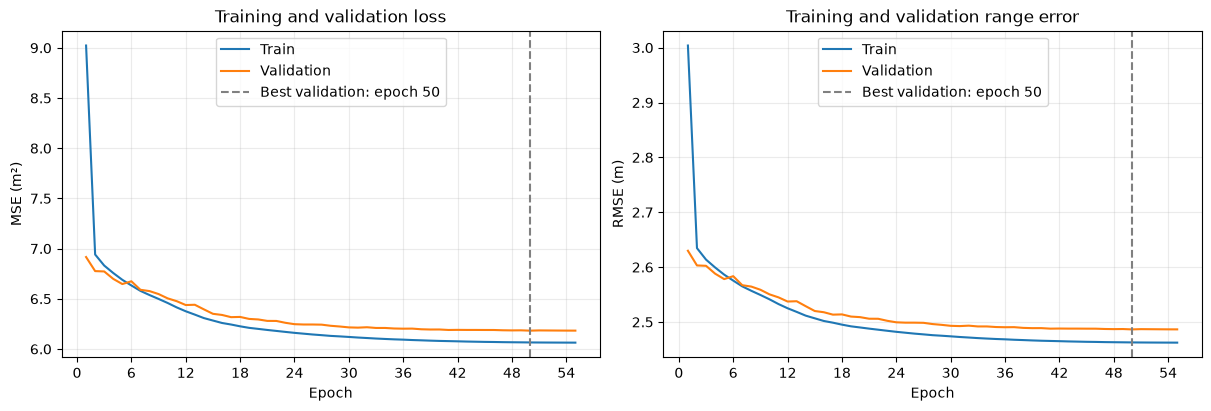

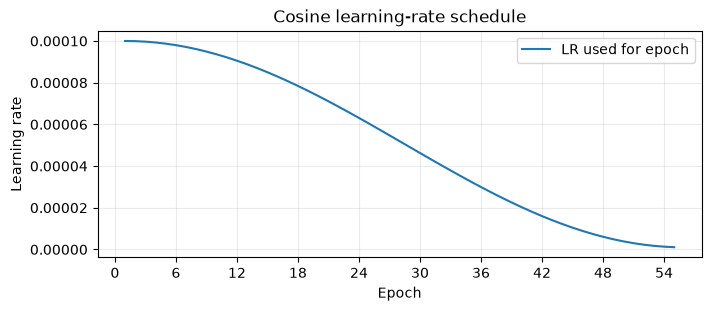

In [59]:
plot_run_history(run_dir, show=True)


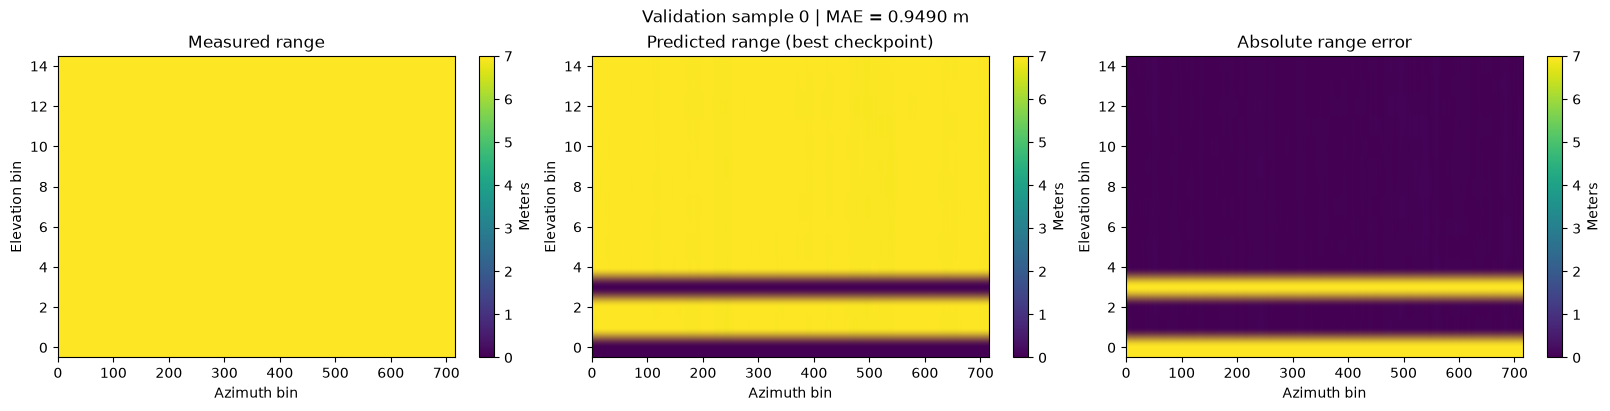

In [60]:
plot_validation_example(model, val_dataset, run_dir, show=True)
